In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression

print("Libraries imported successfully!")

Libraries imported successfully!


In [34]:
# Load the German Credit dataset
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=144)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

# Inspect the dataset
print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst 5 rows of features:")
display(X.head())

print("\nTarget value counts:")
print(y.iloc[:, 0].value_counts())

print("\nFeature column names:")
print(X.columns.tolist())

Dataset loaded successfully!
Features shape: (1000, 20)
Target shape: (1000, 1)

First 5 rows of features:


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201



Target value counts:
class
1    700
2    300
Name: count, dtype: int64

Feature column names:
['Attribute1', 'Attribute2', 'Attribute3', 'Attribute4', 'Attribute5', 'Attribute6', 'Attribute7', 'Attribute8', 'Attribute9', 'Attribute10', 'Attribute11', 'Attribute12', 'Attribute13', 'Attribute14', 'Attribute15', 'Attribute16', 'Attribute17', 'Attribute18', 'Attribute19', 'Attribute20']


In [35]:
# Rename columns using the German Credit dataset definitions
X.columns = [
    "checking_status", "duration", "credit_history", "purpose",
    "credit_amount", "savings_status", "employment",
    "installment_rate", "personal_status", "other_debtors",
    "residence_since", "property", "age", "other_installment_plans",
    "housing", "existing_credits", "job", "dependents",
    "telephone", "foreign_worker"
]

# Convert target: 1 = good credit, 0 = bad credit
y = (y.iloc[:, 0] == 1).astype(int)

# Check missing values
print("Missing values in features:", X.isnull().sum().sum())
print("\nTarget distribution:")
print(y.value_counts())

# Split into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=5,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

Missing values in features: 0

Target distribution:
class
1    700
0    300
Name: count, dtype: int64

Training rows: 700
Testing rows: 300


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

# Preprocess numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Fit only on training data to prevent data leakage
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Numerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Numerical features: 7
Categorical features: 13
Processed training shape: (700, 61)
Processed testing shape: (300, 61)


In [37]:
# Train Model A: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_processed, y_train)

# Predict continuous scores
linear_predictions = linear_model.predict(X_test_processed)

# Train Model B: Logistic Regression
logistic_model = LogisticRegression(max_iter=1000, random_state=5)
logistic_model.fit(X_train_processed, y_train)

# Predict probabilities of good credit
logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

# Convert probabilities to binary predictions
logistic_predictions = (logistic_probabilities >= 0.5).astype(int)

print("Both models trained successfully!")

print("\nFirst 10 linear regression predictions:")
print(np.round(linear_predictions[:10], 3))

print("\nFirst 10 logistic regression probabilities:")
print(np.round(logistic_probabilities[:10], 3))

print("\nFirst 10 logistic classifications:")
print(logistic_predictions[:10])

Both models trained successfully!

First 10 linear regression predictions:
[0.703 0.533 0.675 0.549 0.266 0.75  0.741 0.565 0.884 0.681]

First 10 logistic regression probabilities:
[0.759 0.548 0.627 0.493 0.224 0.857 0.789 0.603 0.926 0.741]

First 10 logistic classifications:
[1 1 1 0 0 1 1 1 1 1]


In [38]:
from sklearn.metrics import confusion_matrix

# Threshold linear regression at its test-set median
linear_threshold = np.median(linear_predictions)
linear_classes = (linear_predictions >= linear_threshold).astype(int)

# Logistic regression already uses threshold 0.5
logistic_classes = (logistic_probabilities >= 0.5).astype(int)

# Compare the two classification approaches
cm = confusion_matrix(
    linear_classes,
    logistic_classes,
    labels=[0, 1]
)

mismatches = np.sum(linear_classes != logistic_classes)
mismatch_percentage = mismatches / len(y_test) * 100

print("Linear regression median threshold:", round(linear_threshold, 4))
print("\nConfusion matrix (rows = linear, columns = logistic):")
print(cm)

print("\nMismatched cases:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")
print("Matching cases:", len(y_test) - mismatches)

Linear regression median threshold: 0.6835

Confusion matrix (rows = linear, columns = logistic):
[[ 71  79]
 [  0 150]]

Mismatched cases: 79
Mismatch percentage: 26.33 %
Matching cases: 221


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report
)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy:",
      round(accuracy_score(y_test, logistic_classes), 4))

print("Precision:",
      round(precision_score(y_test, logistic_classes), 4))

print("Recall:",
      round(recall_score(y_test, logistic_classes), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, logistic_probabilities), 4))

print("\nClassification Report:")
print(classification_report(y_test, logistic_classes))

Logistic Regression Performance
--------------------------------
Accuracy: 0.7367
Precision: 0.786
Recall: 0.8571
ROC-AUC: 0.7952

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.46      0.51        90
           1       0.79      0.86      0.82       210

    accuracy                           0.74       300
   macro avg       0.68      0.66      0.66       300
weighted avg       0.72      0.74      0.73       300



In [40]:
!pip -q install statsmodels

import statsmodels.api as sm
import pandas as pd
import numpy as np

# Combine the original training features with the target
train_data = X_train.copy()
train_data["approval"] = y_train

# Define age groups
train_data["age_group"] = np.where(
    train_data["age"] < 30,
    "Younger",
    "Older"
)

print("Age group counts:")
print(train_data["age_group"].value_counts())

print("\nApproval-proxy rate by age group:")
print(train_data.groupby("age_group")["approval"].mean().round(3))

Age group counts:
age_group
Older      444
Younger    256
Name: count, dtype: int64

Approval-proxy rate by age group:
age_group
Older      0.739
Younger    0.633
Name: approval, dtype: float64


In [41]:
# Select numerical and categorical features
numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()

# Create a dataframe of the already processed training features
feature_names = preprocessor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

# Add a constant for statsmodels
X_train_df = sm.add_constant(X_train_df, has_constant="add")

# Full model
full_model = sm.Logit(y_train, X_train_df).fit(disp=False)

# Create the age groups using the original training data
younger_idx = X_train["age"] < 30
older_idx = X_train["age"] >= 30

# Fit subgroup models with the same processed features
younger_model = sm.Logit(
    y_train.loc[younger_idx],
    X_train_df.loc[younger_idx]
).fit(disp=False)

older_model = sm.Logit(
    y_train.loc[older_idx],
    X_train_df.loc[older_idx]
).fit(disp=False)

# Compare the age coefficient and its confidence interval
age_feature = "num__age"

results = []

for name, model in [
    ("Full dataset", full_model),
    ("Younger (<30)", younger_model),
    ("Older (>=30)", older_model)
]:
    results.append({
        "Group": name,
        "Age coefficient": model.params[age_feature],
        "CI lower": model.conf_int().loc[age_feature, 0],
        "CI upper": model.conf_int().loc[age_feature, 1],
        "p-value": model.pvalues[age_feature]
    })

age_results = pd.DataFrame(results)
display(age_results.round(4))

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,Group,Age coefficient,CI lower,CI upper,p-value
0,Full dataset,0.1310,-0.1105,0.3724,0.2877
1,Younger (<30),1.3425,-0.4821,3.1671,0.1493
2,Older (>=30),0.0012,-0.3453,0.3478,0.9944


In [42]:
from sklearn.linear_model import LogisticRegression
import pandas as pd
import numpy as np

# Fit regularized logistic regression on the full training data
stable_full = LogisticRegression(
    max_iter=5000, C=1.0, solver="liblinear", random_state=5
)
stable_full.fit(X_train_processed, y_train)

# Fit models for the two age groups
stable_younger = LogisticRegression(
    max_iter=5000, C=1.0, solver="liblinear", random_state=5
)
stable_younger.fit(
    X_train_processed[younger_idx],
    y_train.loc[younger_idx]
)

stable_older = LogisticRegression(
    max_iter=5000, C=1.0, solver="liblinear", random_state=5
)
stable_older.fit(
    X_train_processed[older_idx],
    y_train.loc[older_idx]
)

# Find the age feature's index
age_index = list(feature_names).index("num__age")

# Compare age coefficients
stable_results = pd.DataFrame({
    "Group": ["Full dataset", "Younger (<30)", "Older (>=30)"],
    "Age coefficient": [
        stable_full.coef_[0][age_index],
        stable_younger.coef_[0][age_index],
        stable_older.coef_[0][age_index]
    ]
})

display(stable_results.round(4))

,Group,Age coefficient
0,Full dataset,0.1219
1,Younger (<30),0.4271
2,Older (>=30),0.0050


In [43]:
import statsmodels.formula.api as smf

# Build a simple analysis dataset from the training data
age_data = X_train[["age"]].copy()
age_data["approval"] = y_train
age_data["age_group"] = np.where(
    age_data["age"] < 30, "Younger", "Older"
)

# Center age to make the model easier to interpret
age_data["age_centered"] = age_data["age"] - age_data["age"].mean()

# Test whether the age association differs between age groups
interaction_model = smf.logit(
    "approval ~ age_centered * C(age_group)",
    data=age_data
).fit(disp=False)

print(interaction_model.summary())
print("\n95% confidence intervals:")
display(interaction_model.conf_int().round(4))

                           Logit Regression Results                           
Dep. Variable:               approval   No. Observations:                  700
Model:                          Logit   Df Residuals:                      696
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                 0.01093
Time:                        06:31:51   Log-Likelihood:                -422.93
converged:                       True   LL-Null:                       -427.61
Covariance Type:            nonrobust   LLR p-value:                   0.02506
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
Intercept                                1.0619      0.127      8.394      0.000       0.814       1.310
C(age_group)[T.Younger]                 -0.0980      

,0,1
Intercept,0.8139,1.3098
C(age_group)[T.Younger],-1.1689,0.9730
age_centered,-0.0250,0.0175
age_centered:C(age_group)[T.Younger],-0.0557,0.1450


In [44]:
# Compare good-credit rates by personal status
status_analysis = X_train[["personal_status"]].copy()
status_analysis["approval"] = y_train

status_summary = status_analysis.groupby("personal_status").agg(
    total_cases=("approval", "size"),
    good_credit_rate=("approval", "mean")
)

status_summary["good_credit_rate"] *= 100

display(status_summary.round(2))

,total_cases,good_credit_rate
personal_status,,
A91,34,55.88
A92,212,66.51
A93,390,72.05
A94,64,76.56


In [45]:
import statsmodels.formula.api as smf

# Use original, readable columns for this analysis
status_model_data = X_train[
    ["personal_status", "credit_amount"]
].copy()

status_model_data["approval"] = y_train

# Fit logistic regression
status_model = smf.logit(
    "approval ~ C(personal_status) + credit_amount",
    data=status_model_data
).fit(disp=False)

print(status_model.summary())

print("\n95% confidence intervals:")
display(status_model.conf_int().round(4))

                           Logit Regression Results                           
Dep. Variable:               approval   No. Observations:                  700
Model:                          Logit   Df Residuals:                      695
Method:                           MLE   Df Model:                            4
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                 0.02512
Time:                        06:31:51   Log-Likelihood:                -416.86
converged:                       True   LL-Null:                       -427.61
Covariance Type:            nonrobust   LLR p-value:                 0.0002535
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                     0.6772      0.368      1.841      0.066      -0.044       1.398
C(personal_status)[T.A92]     0.3230      0.381      0.847      0.397      -0.424     

,0,1
Intercept,-0.0439,1.3982
C(personal_status)[T.A92],-0.4241,1.0701
C(personal_status)[T.A93],-0.0099,1.4360
C(personal_status)[T.A94],-0.1565,1.6519
credit_amount,-0.0002,-0.0001


In [46]:
# Define two groups from personal status
status_groups = {
    "Group A (A91/A92)": ["A91", "A92"],
    "Group B (A93/A94)": ["A93", "A94"]
}

subgroup_credit_results = []

for group_name, codes in status_groups.items():
    subset = X_train[X_train["personal_status"].isin(codes)].copy()
    subset["approval"] = y_train.loc[subset.index]

    model = smf.logit(
        "approval ~ credit_amount + age + duration",
        data=subset
    ).fit(disp=False)

    subgroup_credit_results.append({
        "Group": group_name,
        "Cases": len(subset),
        "Credit amount coefficient": model.params["credit_amount"],
        "95% CI lower": model.conf_int().loc["credit_amount", 0],
        "95% CI upper": model.conf_int().loc["credit_amount", 1],
        "p-value": model.pvalues["credit_amount"]
    })

display(pd.DataFrame(subgroup_credit_results).round(6))

,Group,Cases,Credit amount coefficient,95% CI lower,95% CI upper,p-value
0,Group A (A91/A92),246,0.000051,-0.000088,0.000191,0.468297
1,Group B (A93/A94),454,-0.000070,-0.000157,0.000017,0.113529


In [47]:
# Fit the same formula on the full training dataset
full_credit_data = X_train[
    ["credit_amount", "age", "duration"]
].copy()

full_credit_data["approval"] = y_train

full_credit_model = smf.logit(
    "approval ~ credit_amount + age + duration",
    data=full_credit_data
).fit(disp=False)

print("Full training dataset — credit amount coefficient")
print("Coefficient:", round(
    full_credit_model.params["credit_amount"], 8
))
print("95% confidence interval:")
print(full_credit_model.conf_int().loc["credit_amount"].round(8))
print("p-value:", round(
    full_credit_model.pvalues["credit_amount"], 6
))

Full training dataset — credit amount coefficient
Coefficient: -2.889e-05
95% confidence interval:
0   -0.000102
1    0.000044
Name: credit_amount, dtype: float64
p-value: 0.439697


In [48]:

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# Use all 20 original predictors and the training target
ovb_data = X_train.copy()
ovb_data["approval"] = y_train

# Convert categorical variables to category dtype
categorical_cols = ovb_data.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols:
    ovb_data[col] = ovb_data[col].astype("category")

# Full model: all 20 predictors
predictors = X_train.columns.tolist()

full_formula = (
    "approval ~ "
    + " + ".join(
        f"C({col})" if col in categorical_cols else col
        for col in predictors
    )
)

# Reduced model: omit checking_status
reduced_predictors = [
    col for col in predictors if col != "checking_status"
]

reduced_formula = (
    "approval ~ "
    + " + ".join(
        f"C({col})" if col in categorical_cols else col
        for col in reduced_predictors
    )
)

# Fit both logistic regression models
full_model = smf.logit(full_formula, data=ovb_data).fit(disp=False, maxiter=200)
reduced_model = smf.logit(reduced_formula, data=ovb_data).fit(disp=False, maxiter=200)

# Compare the four coefficients used in the report
compare_cols = [
    "credit_amount",
    "age",
    "duration",
    "installment_rate"
]

ovb_table = pd.DataFrame({
    "Predictor": compare_cols,
    "Full coefficient": [
        full_model.params.get(c, np.nan) for c in compare_cols
    ],
    "Reduced coefficient": [
        reduced_model.params.get(c, np.nan) for c in compare_cols
    ]
})

ovb_table["Absolute change"] = (
    ovb_table["Reduced coefficient"] -
    ovb_table["Full coefficient"]
).abs()

ovb_table["% change"] = (
    ovb_table["Absolute change"] /
    ovb_table["Full coefficient"].abs().replace(0, np.nan)
) * 100

display(ovb_table.round(6))
print("Full model converged:", full_model.mle_retvals["converged"])
print("Reduced model converged:", reduced_model.mle_retvals["converged"])


,Predictor,Full coefficient,Reduced coefficient,Absolute change,% change
0,credit_amount,-0.000146,-0.000144,0.000002,1.654436
1,age,0.011734,0.014400,0.002665,22.714441
2,duration,-0.022638,-0.025317,0.002678,11.830543
3,installment_rate,-0.377599,-0.373549,0.004050,1.072514


Full model converged: True
Reduced model converged: True


In [49]:
# Collect test predictions and actual outcomes
adversarial_data = X_test.copy()
adversarial_data["actual"] = y_test
adversarial_data["probability"] = logistic_probabilities
adversarial_data["predicted"] = logistic_classes

# Identify confident incorrect predictions
adversarial_data["error_type"] = np.where(
    (adversarial_data["probability"] >= 0.75) &
    (adversarial_data["actual"] == 0),
    "False positive",
    np.where(
        (adversarial_data["probability"] <= 0.25) &
        (adversarial_data["actual"] == 1),
        "False negative",
        "Other"
    )
)

# Keep only confident errors
adversarial_subset = adversarial_data[
    adversarial_data["error_type"] != "Other"
].copy()

# Randomly select 50 if there are more than 50
if len(adversarial_subset) > 50:
    adversarial_subset = adversarial_subset.sample(
        n=50, random_state=5
    )

print("Confident incorrect cases:", len(adversarial_subset))
print("Percentage of test set:",
      round(len(adversarial_subset) / len(y_test) * 100, 2), "%")

print("\nError types:")
print(adversarial_subset["error_type"].value_counts())

print("\nFirst 10 selected cases:")
display(adversarial_subset.head(10))

Confident incorrect cases: 20
Percentage of test set: 6.67 %

Error types:
error_type
False positive    17
False negative     3
Name: count, dtype: int64

First 10 selected cases:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_debtors,...,housing,existing_credits,job,dependents,telephone,foreign_worker,actual,probability,predicted,error_type
948,A14,18,A32,A42,1533,A61,A72,4,A94,A102,...,A152,1,A172,2,A191,A201,0,0.846401,1,False positive
405,A12,24,A32,A43,2039,A61,A72,1,A94,A101,...,A152,1,A173,1,A192,A201,0,0.850627,1,False positive
827,A14,18,A30,A49,4165,A61,A73,2,A93,A101,...,A152,2,A173,2,A191,A201,0,0.767557,1,False positive
861,A14,18,A33,A49,2169,A61,A73,4,A94,A101,...,A152,1,A173,1,A192,A201,0,0.930015,1,False positive
278,A14,6,A32,A42,4611,A61,A72,1,A92,A101,...,A152,1,A173,1,A191,A201,0,0.911932,1,False positive
457,A11,12,A32,A41,3386,A61,A75,3,A93,A101,...,A153,1,A173,1,A192,A201,0,0.777471,1,False positive
633,A14,9,A32,A42,1980,A61,A72,2,A92,A102,...,A151,2,A173,1,A191,A201,0,0.785445,1,False positive
594,A11,24,A31,A410,1358,A65,A75,4,A93,A101,...,A152,1,A174,1,A192,A201,0,0.798523,1,False positive
746,A11,15,A32,A40,2511,A61,A71,1,A92,A101,...,A151,1,A173,1,A191,A201,1,0.235584,0,False negative
966,A12,27,A34,A43,2520,A63,A73,4,A93,A101,...,A152,2,A172,1,A191,A201,0,0.752825,1,False positive


In [50]:
# Compare adversarial cases with the full test set

print("AGE COMPARISON")
print("Adversarial subset:")
print(adversarial_subset["age"].describe().round(2))

print("\nFull test set:")
print(X_test["age"].describe().round(2))


print("\nPERSONAL STATUS: ADVERSARIAL VS FULL TEST SET")

status_comparison = pd.concat([
    adversarial_subset["personal_status"]
        .value_counts(normalize=True)
        .mul(100)
        .rename("Adversarial (%)"),

    X_test["personal_status"]
        .value_counts(normalize=True)
        .mul(100)
        .rename("Full test set (%)")
], axis=1).fillna(0)

display(status_comparison.round(2))


print("\nNUMERICAL CHARACTERISTICS")

characteristics = pd.DataFrame({
    "Adversarial mean": adversarial_subset[
        ["credit_amount", "duration", "age"]
    ].mean(),

    "Test set mean": X_test[
        ["credit_amount", "duration", "age"]
    ].mean()
})

characteristics["Difference"] = (
    characteristics["Adversarial mean"]
    - characteristics["Test set mean"]
)

display(characteristics.round(2))

AGE COMPARISON
Adversarial subset:
count    20.00
mean     29.65
std       7.23
min      19.00
25%      23.00
50%      28.00
75%      35.25
max      43.00
Name: age, dtype: float64

Full test set:
count    300.00
mean      35.93
std       11.85
min       19.00
25%       26.00
50%       33.00
75%       42.00
max       74.00
Name: age, dtype: float64

PERSONAL STATUS: ADVERSARIAL VS FULL TEST SET


,Adversarial (%),Full test set (%)
personal_status,,
A93,40.0,52.67
A92,35.0,32.67
A94,25.0,9.33
A91,0.0,5.33



NUMERICAL CHARACTERISTICS


,Adversarial mean,Test set mean,Difference
credit_amount,3244.05,3370.73,-126.68
duration,21.15,20.97,0.18
age,29.65,35.93,-6.28


In [51]:
# Prepare fairness analysis on the test set
fairness_data = X_test[["personal_status"]].copy()
fairness_data["actual"] = y_test
fairness_data["probability"] = logistic_probabilities

# Group A: A91/A92; Group B: A93/A94
fairness_data["group"] = np.where(
    fairness_data["personal_status"].isin(["A91", "A92"]),
    "A",
    "B"
)

# Test all required thresholds
thresholds = np.round(np.arange(0.05, 0.96, 0.10), 2)

fairness_results = []

for threshold in thresholds:
    fairness_data["predicted"] = (
        fairness_data["probability"] >= threshold
    ).astype(int)

    group_metrics = {}

    for group in ["A", "B"]:
        subset = fairness_data[fairness_data["group"] == group]

        actual = subset["actual"]
        predicted = subset["predicted"]

        tp = ((actual == 1) & (predicted == 1)).sum()
        fp = ((actual == 0) & (predicted == 1)).sum()
        fn = ((actual == 1) & (predicted == 0)).sum()
        tn = ((actual == 0) & (predicted == 0)).sum()

        group_metrics[group] = {
            "selection_rate": predicted.mean(),
            "TPR": tp / (tp + fn) if (tp + fn) else np.nan,
            "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
            "PPV": tp / (tp + fp) if (tp + fp) else np.nan
        }

    A = group_metrics["A"]
    B = group_metrics["B"]

    def ratio(a, b):
        return a / b if pd.notna(a) and pd.notna(b) and b != 0 else np.nan

    dp = ratio(A["selection_rate"], B["selection_rate"])
    tpr_ratio = ratio(A["TPR"], B["TPR"])
    fpr_ratio = ratio(A["FPR"], B["FPR"])
    eo = np.nanmin([tpr_ratio, fpr_ratio])
    pp = ratio(A["PPV"], B["PPV"])

    fairness_results.append({
        "Threshold": threshold,
        "DP": dp,
        "EO": eo,
        "PP": pp
    })

fairness_table = pd.DataFrame(fairness_results)
display(fairness_table.round(4))

,Threshold,DP,EO,PP
0,0.05,1.0000,1.0000,0.8334
1,0.15,0.9896,0.9937,0.8421
2,0.25,0.9624,0.9789,0.8476
3,0.35,0.9172,0.9204,0.8364
4,0.45,0.8571,0.8978,0.8786
5,0.55,0.8215,0.7742,0.9180
6,0.65,0.7956,0.7287,0.9480
7,0.75,0.6746,0.4554,0.9990
8,0.85,0.5370,0.3123,1.0128
9,0.95,0.4737,0.5684,1.0000


In [52]:

print("Fairness table columns:", fairness_table.columns.tolist())

print("Accuracy column available:",
      "Accuracy" in fairness_table.columns)

Fairness table columns: ['Threshold', 'DP', 'EO', 'PP']
Accuracy column available: False


In [53]:
# Reproduce threshold trade-off calculations

threshold_results = fairness_table.sort_values("Threshold").copy()

# Calculate accuracy directly for every threshold
threshold_results["Accuracy"] = [
    ((logistic_probabilities >= t).astype(int) == np.asarray(y_test)).mean()
    for t in threshold_results["Threshold"]
]

# Compare thresholds 0.45 and 0.75
low_threshold = threshold_results.loc[
    np.isclose(threshold_results["Threshold"], 0.45)
].iloc[0]

high_threshold = threshold_results.loc[
    np.isclose(threshold_results["Threshold"], 0.75)
].iloc[0]

def percent_change(old, new):
    return ((new - old) / abs(old)) * 100 if old != 0 else np.nan

tradeoff_results = pd.DataFrame({
    "Metric": ["DP", "EO", "PP", "Accuracy"],
    "At threshold 0.45": [
        low_threshold["DP"],
        low_threshold["EO"],
        low_threshold["PP"],
        low_threshold["Accuracy"]
    ],
    "At threshold 0.75": [
        high_threshold["DP"],
        high_threshold["EO"],
        high_threshold["PP"],
        high_threshold["Accuracy"]
    ]
})

tradeoff_results["Percentage change (0.45 vs 0.75)"] = [
    percent_change(high_threshold["DP"], low_threshold["DP"]),
    percent_change(high_threshold["EO"], low_threshold["EO"]),
    percent_change(high_threshold["PP"], low_threshold["PP"]),
    percent_change(high_threshold["Accuracy"], low_threshold["Accuracy"])
]

display(tradeoff_results.round(4))

,Metric,At threshold 0.45,At threshold 0.75,Percentage change (0.45 vs 0.75)
0,DP,0.8571,0.6746,27.0533
1,EO,0.8978,0.4554,97.1429
2,PP,0.8786,0.9990,-12.0519
3,Accuracy,0.7633,0.6767,12.8079


In [54]:

# Reproduce personal-status subgroup sizes and good-credit rates
subgroup_data = X_train[["personal_status"]].copy()
subgroup_data["approval"] = np.asarray(y_train).ravel()

subgroup_data["Group"] = np.where(
    subgroup_data["personal_status"].isin(["A91", "A92"]),
    "Group A (A91/A92)",
    "Group B (A93/A94)"
)

subgroup_summary = subgroup_data.groupby(
    "Group", observed=True
).agg(
    Applicants=("approval", "size"),
    Good_credit_count=("approval", "sum"),
    Good_credit_rate=("approval", "mean")
).reset_index()

subgroup_summary["Good_credit_rate (%)"] = (
    subgroup_summary["Good_credit_rate"] * 100
)

display(subgroup_summary.round(4))


,Group,Applicants,Good_credit_count,Good_credit_rate,Good_credit_rate (%)
0,Group A (A91/A92),246,160,0.6504,65.0407
1,Group B (A93/A94),454,330,0.7269,72.6872


In [55]:

# Reproduce personal-status group sizes in the test set

test_group_data = X_test[["personal_status"]].copy()

test_group_data["Group"] = np.where(
    test_group_data["personal_status"].isin(["A91", "A92"]),
    "Group A (A91/A92)",
    "Group B (A93/A94)"
)

test_group_summary = test_group_data.groupby("Group").size().reset_index(
    name="Test_applicants"
)

display(test_group_summary)


,Group,Test_applicants
0,Group A (A91/A92),114
1,Group B (A93/A94),186


In [56]:

# Reproduce the Wald-style comparison of subgroup credit-amount coefficients

from scipy.stats import norm

# Coefficients and 95% confidence intervals from the subgroup models
coef_A = 5.1e-05
ci_A = (-8.8e-05, 1.91e-04)

coef_B = -7.0e-05
ci_B = (-1.57e-04, 1.7e-05)

# Approximate standard errors from 95% confidence intervals
se_A = (ci_A[1] - ci_A[0]) / (2 * 1.96)
se_B = (ci_B[1] - ci_B[0]) / (2 * 1.96)

# Difference between coefficients
difference = coef_A - coef_B
se_difference = np.sqrt(se_A**2 + se_B**2)

z_statistic = difference / se_difference
p_value = 2 * norm.sf(abs(z_statistic))

wald_results = pd.DataFrame({
    "Quantity": [
        "Group A coefficient",
        "Group B coefficient",
        "Difference (A - B)",
        "Approx. SE of difference",
        "Wald z statistic",
        "Two-sided p-value"
    ],
    "Value": [
        coef_A,
        coef_B,
        difference,
        se_difference,
        z_statistic,
        p_value
    ]
})

display(wald_results.round(6))


,Quantity,Value
0,Group A coefficient,0.000051
1,Group B coefficient,-0.000070
2,Difference (A - B),0.000121
3,Approx. SE of difference,0.000084
4,Wald z statistic,1.442529
5,Two-sided p-value,0.149153


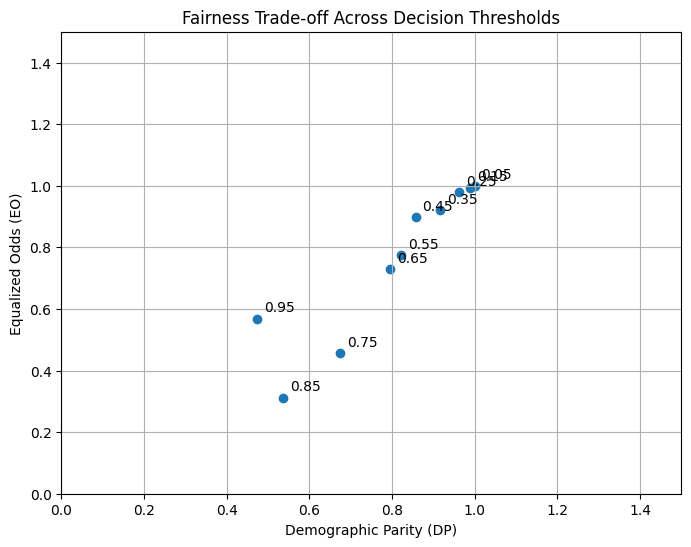

In [57]:
# Plot the fairness trade-off
plt.figure(figsize=(8, 6))

plt.scatter(
    fairness_table["DP"],
    fairness_table["EO"]
)

for _, row in fairness_table.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP"], row["EO"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Demographic Parity (DP)")
plt.ylabel("Equalized Odds (EO)")
plt.title("Fairness Trade-off Across Decision Thresholds")

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.grid(True)
plt.show()

In [58]:
# Compare two thresholds using your fairness table
low = fairness_table[fairness_table["Threshold"] == 0.45].iloc[0]
high = fairness_table[fairness_table["Threshold"] == 0.75].iloc[0]

dp_change = (high["DP"] - low["DP"]) / low["DP"] * 100
eo_change = (high["EO"] - low["EO"]) / low["EO"] * 100

print("Threshold 0.45:")
print("DP =", round(low["DP"], 4))
print("EO =", round(low["EO"], 4))
print("PP =", round(low["PP"], 4))

print("\nThreshold 0.75:")
print("DP =", round(high["DP"], 4))
print("EO =", round(high["EO"], 4))
print("PP =", round(high["PP"], 4))

print("\nDP percentage change:", round(dp_change, 2), "%")
print("EO percentage change:", round(eo_change, 2), "%")

Threshold 0.45:
DP = 0.8571
EO = 0.8978
PP = 0.8786

Threshold 0.75:
DP = 0.6746
EO = 0.4554
PP = 0.999

DP percentage change: -21.29 %
EO percentage change: -49.28 %


In [59]:
# Display final fairness results
display(fairness_table.round(4))

# Find the threshold closest to ideal (1.0) across all three metrics
fairness_table["distance_from_ideal"] = (
    (fairness_table["DP"] - 1).abs()
    + (fairness_table["EO"] - 1).abs()
    + (fairness_table["PP"] - 1).abs()
)

best_threshold = fairness_table.loc[
    fairness_table["distance_from_ideal"].idxmin()
]

print("\nThreshold closest to ideal across DP, EO and PP:")
print(best_threshold[["Threshold", "DP", "EO", "PP"]])

,Threshold,DP,EO,PP
0,0.05,1.0000,1.0000,0.8334
1,0.15,0.9896,0.9937,0.8421
2,0.25,0.9624,0.9789,0.8476
3,0.35,0.9172,0.9204,0.8364
4,0.45,0.8571,0.8978,0.8786
5,0.55,0.8215,0.7742,0.9180
6,0.65,0.7956,0.7287,0.9480
7,0.75,0.6746,0.4554,0.9990
8,0.85,0.5370,0.3123,1.0128
9,0.95,0.4737,0.5684,1.0000



Threshold closest to ideal across DP, EO and PP:
Threshold    0.050000
DP           1.000000
EO           1.000000
PP           0.833396
Name: 0, dtype: float64


In [60]:
from sklearn.metrics import accuracy_score

accuracy_results = []

for threshold in thresholds:
    predictions = (logistic_probabilities >= threshold).astype(int)

    accuracy_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions)
    })

accuracy_table = pd.DataFrame(accuracy_results)

fairness_table = fairness_table.merge(
    accuracy_table,
    on="Threshold",
    how="left"
)

display(fairness_table.round(4))

,Threshold,DP,EO,PP,distance_from_ideal,Accuracy
0,0.05,1.0000,1.0000,0.8334,0.1666,0.7000
1,0.15,0.9896,0.9937,0.8421,0.1746,0.7200
2,0.25,0.9624,0.9789,0.8476,0.2111,0.7367
3,0.35,0.9172,0.9204,0.8364,0.3260,0.7333
4,0.45,0.8571,0.8978,0.8786,0.3665,0.7633
5,0.55,0.8215,0.7742,0.9180,0.4863,0.7433
6,0.65,0.7956,0.7287,0.9480,0.5277,0.7333
7,0.75,0.6746,0.4554,0.9990,0.8710,0.6767
8,0.85,0.5370,0.3123,1.0128,1.1636,0.5900
9,0.95,0.4737,0.5684,1.0000,0.9579,0.4333


In [61]:
# Save key analysis tables as CSV files

fairness_table.to_csv("fairness_results.csv", index=False)
ovb_table.to_csv("omitted_variable_results.csv", index=False)
age_results.to_csv("age_subgroup_results.csv", index=False)
adversarial_subset.to_csv("adversarial_cases.csv", index=True)

print("Key analysis tables saved successfully.")

Key analysis tables saved successfully.
